  0%|          | 0/19 [00:00<?, ?it/s]

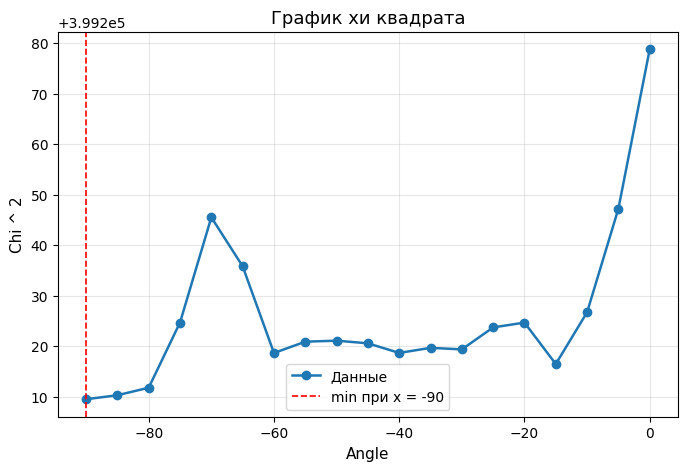

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import trange
from snewpy.flux import Container
from scipy.stats import poisson

def load_model(angle, distance=1.0): # читаем модельные данные 
    data = Container.load(f'ibd_Juno_rate.{angle:d}.npz').array.squeeze().to_value('')
    data *= (1.0 / distance) ** 2          # поправка на расстояние
    return data

def calc_chi2(n_samp, n_model):
    return -2.0 * np.sum(poisson.logpmf(n_samp, n_model))
    
distance = 1
samples = np.random.poisson(lam = load_model(-80, distance))
chi2_dict = {}
for ang in trange(-90, 2, 5):
    model = load_model(ang, distance)
    chi2_dict[ang] = calc_chi2(samples, model)
chi2 = np.stack(list(chi2_dict.values()))
angles = np.array(list(chi2_dict.keys()))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(angles, chi2, 'o-', lw=1.8, ms=6, color='C0', label='Данные')
ax.set_xlabel('Angle', fontsize=11)
ax.set_ylabel('Chi ^ 2', fontsize=11)
ax.set_title('График хи квадрата', fontsize=13)
ax.grid(alpha=0.3)
i_min = np.argmin(chi2)
ax.axvline(angles[i_min], color='red', ls='--', lw=1.2, label=f'min при x = {angles[i_min]}')
ax.legend()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import trange
from snewpy.flux import Container
from scipy.stats import poisson

def load_model(angle, distance=1.0):
    data = Container.load(f'ibd_Juno_rate.{angle:d}.npz').array.squeeze().to_value('')
    data *= (1.0 / distance) ** 2
    return data

def calc_chi2(n_samp, n_model):
    return -2.0 * np.sum(poisson.logpmf(n_samp, n_model))

distance = 0.5
angles = np.arange(-90, 2, 5)
models = {ang: load_model(ang, distance) for ang in angles}
true_angle = -45

rng = np.random.default_rng(546)
chi2_all = np.zeros((100, len(angles)))

for i in trange(100):
    samples = rng.poisson(lam=models[true_angle])
    for j, ang in enumerate(angles):
        chi2_all[i, j] = calc_chi2(samples, models[ang])

fig, ax = plt.subplots(figsize=(8, 5))
for i in range(100):
    ax.plot(angles, chi2_all[i], color='C0', alpha=0.2, lw=0.8)
    
ax.plot(angles, chi2_all.mean(axis=0), color='C0', lw=2.5)
#ax.axvline(true_angle, color='green', ls='-', lw=1.2)
i_min = np.argmin(chi2_all.mean(axis=0))
ax.axvline(angles[i_min], color='red', ls='--', lw=1.2, label=f'min при x = {angles[i_min]}')
ax.set_xlabel('Angle')
ax.set_ylabel('Chi ^ 2')
ax.set_title('График хи квадрата')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

  0%|          | 0/100 [00:00<?, ?it/s]